# 🎬 MovieMatch: Hybrid Movie Recommender

**Executive summary.** This notebook trains, validates and exports the recommendation model behind the MovieMatch web app. It fuses collaborative filtering with content similarity, learned from 100k real MovieLens ratings, into one embedding per movie. In an honest temporal hold-out it beats a popularity baseline by **~43% NDCG@10** while still recommending across more than 20% of the catalogue.

| | |
|---|---|
| **Dataset** | MovieLens `ml-latest-small` (GroupLens): 100,836 ratings · 610 users · 9,742 movies |
| **Model** | Truncated-SVD collaborative factors ⊕ TF-IDF/LSA content factors → 80-d unit vectors |
| **Serving** | The vectors are exported to `backend/model/`; the Node API "folds in" each user in ~1 ms |
| **Runtime** | ~30 s on a laptop CPU, with no GPU required |

## 🧭 Table of contents

1. [Phase 1: Environment Setup & Hardware Check](#phase1)
2. [Phase 2: Exploratory Data Analysis & Preprocessing](#phase2)
3. [Phase 3: Model Architecture & Compilation](#phase3)
4. [Phase 4: Training Pipeline](#phase4)
5. [Phase 5: Comprehensive Evaluation](#phase5)
6. [Conclusions & Next Steps](#conclusions)

> 📝 **Prerequisites**
> - Python ≥ 3.10 with `numpy`, `scipy` and `matplotlib` (`pip install -r ml/requirements.txt matplotlib`).
> - Run from anywhere inside the repo: the notebook locates the `moviematch_ml` package automatically.
> - The dataset is downloaded on first run (~1 MB) if it isn't already in `ml/data/raw/`.

> 🧱 **Single source of truth.** The core maths (`collaborative_factors`, `content_factors`, `hybrid`, `user_profiles`, `rank_metrics`) lives in the `moviematch_ml` package, which is unit-tested and is what produces the production model. This notebook *imports* those functions and adds the narrative, validation, experiment tracking and evaluation around them, so the notebook and production can never drift apart.

---
<a id="phase1"></a>
# ⚙️ Phase 1: Environment Setup & Hardware Check

### 1.1 Imports, paths and run configuration

**The Goal:** load every dependency once, locate the project package, and freeze every tunable knob in one immutable config object.

**The Why:** a frozen `dataclass` makes the run reproducible and self-documenting. The config is hashed later to name the experiment checkpoint, so changing any value starts a fresh experiment log instead of silently mixing results.

**Key Parameters**

| Parameter | Value | Meaning |
|---|---|---|
| `seed` | 42 | Global NumPy seed (the SVD solver also uses a fixed `random_state=0`) |
| `min_ratings_per_movie` | 5 | Drop movies with fewer ratings: too little signal to learn from |
| `test_fraction` | 0.2 | Share of each user's **most recent** ratings held out |
| `like_threshold` | 4.0 | A rating ≥ 4★ counts as "liked" (the ground truth) |
| `top_k` | 10 | Length of the recommendation list being evaluated |
| `collab_dims_grid` | 24 / 48 / 96 | Candidate ranks for the collaborative SVD |
| `content_dims` | 32 | LSA topics for the content view |
| `alpha_grid` | 0 … 1 | Weight of collaborative vs content similarity |
| `beta_grid` | 0 … 0.7 | Strength of the popularity prior |
| `min_coverage` | 0.20 | Model-selection constraint: ≥ 20% of the catalogue must be recommended |
| `export_to_backend` | `False` | When `True`, overwrite the production model in `backend/model/` |

In [1]:
from __future__ import annotations

import hashlib
import json
import logging
import os
import platform
import shutil
import subprocess
import sys
import time
import urllib.request
import zipfile
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds


def find_ml_root(start: Path | None = None) -> Path:
    """Walk up from ``start`` until the folder that contains ``moviematch_ml`` is found.

    Parameters
    ----------
    start : Path, optional
        Where to begin searching (defaults to the current working directory).

    Returns
    -------
    Path
        The ``ml/`` directory of the repository.
    """
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents, *(p / "ml" for p in [start, *start.parents])]:
        if (candidate / "moviematch_ml").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the moviematch_ml package; run inside the repository.")


ML_ROOT = find_ml_root()
if str(ML_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_ROOT))

from moviematch_ml.data import Dataset, load_movielens, temporal_split  # noqa: E402
from moviematch_ml.evaluate import positives, rank_metrics, seen  # noqa: E402
from moviematch_ml.model import (  # noqa: E402
    collaborative_factors,
    content_documents,
    content_factors,
    hybrid,
    popularity_prior,
    tfidf,
    user_profiles,
)


@dataclass(frozen=True)
class RunConfig:
    """Every tunable knob of the run, in one immutable, hashable place."""

    seed: int = 42
    data_dir: Path = ML_ROOT / "data" / "raw" / "ml-latest-small"
    artifact_dir: Path = ML_ROOT / "artifacts"
    min_ratings_per_movie: int = 5
    test_fraction: float = 0.2
    like_threshold: float = 4.0
    top_k: int = 10
    collab_dims_grid: tuple[int, ...] = (24, 48, 96)
    content_dims: int = 32
    alpha_grid: tuple[float, ...] = (0.0, 0.5, 0.7, 0.8, 0.9, 1.0)
    beta_grid: tuple[float, ...] = (0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7)
    min_coverage: float = 0.20
    export_to_backend: bool = False

    def fingerprint(self) -> str:
        """Short hash of the experiment-defining fields (used to name checkpoints)."""
        fields = {k: v for k, v in asdict(self).items() if k not in {"artifact_dir", "export_to_backend"}}
        return hashlib.sha256(json.dumps(fields, default=str, sort_keys=True).encode()).hexdigest()[:10]


CONFIG = RunConfig()
np.random.seed(CONFIG.seed)
CONFIG.artifact_dir.mkdir(parents=True, exist_ok=True)

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)-7s | %(message)s",
                    datefmt="%H:%M:%S", stream=sys.stdout, force=True)
log = logging.getLogger("moviematch")
log.info("ML root: %s | config fingerprint: %s", ML_ROOT, CONFIG.fingerprint())

16:55:53 | INFO    | ML root: C:\Users\Asus\Documents\project\move recommendation system\ml | config fingerprint: 664ff8f2b4


### 1.2 Presentation helpers

**The Goal:** consistent tables and figures for the rest of the notebook.

**The Why:** Markdown tables render cleanly in Jupyter, VS Code and GitHub. The plot palette reuses the MovieMatch app's ink-on-paper colours, so the figures match the product they describe.

In [2]:
PALETTE: dict[str, str] = {
    "ink": "#16130f", "red": "#e0341b", "mustard": "#e9b23c", "teal": "#1d4b5a",
    "green": "#2d5a3d", "paper": "#f6f0e2", "muted": "#7d705e",
}
plt.rcParams.update({
    "figure.facecolor": PALETTE["paper"], "axes.facecolor": PALETTE["paper"], "savefig.facecolor": PALETTE["paper"],
    "axes.edgecolor": PALETTE["ink"], "axes.labelcolor": PALETTE["ink"], "text.color": PALETTE["ink"],
    "xtick.color": PALETTE["ink"], "ytick.color": PALETTE["ink"], "axes.grid": True, "grid.color": "#d9cdb4",
    "grid.linestyle": "--", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10, "figure.dpi": 110,
})


def show_table(rows: list[dict], columns: list[str] | None = None, title: str | None = None,
               floatfmt: str = "{:.4f}") -> None:
    """Render a list of dicts as a Markdown table.

    Parameters
    ----------
    rows : list of dict
        One dict per row.
    columns : list of str, optional
        Column order (defaults to the keys of the first row).
    title : str, optional
        Bold caption shown above the table.
    floatfmt : str, default "{:.4f}"
        Format applied to float cells.
    """
    columns = columns or list(rows[0])
    fmt = lambda v: floatfmt.format(v) if isinstance(v, float) else str(v)  # noqa: E731
    lines = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
    lines += ["| " + " | ".join(fmt(row.get(c, "")) for c in columns) + " |" for row in rows]
    display(Markdown((f"**{title}**\n\n" if title else "") + "\n".join(lines)))

### 1.3 Hardware check

**The Goal:** report the CPU, any GPU/TPU, and the BLAS library NumPy links against.

**The Why:** this model is **sparse linear algebra**: a truncated SVD of a 610 × 3,650 matrix with ~1.5% non-zeros, plus dense matrix–vector products. That runs in seconds on a CPU, and moving data to a GPU would cost more than it saves at this scale. The check still matters: it documents the environment for reproducibility, and it tells you whether a GPU path is available if you scale up to `ml-latest` (33M ratings), where GPU ALS (e.g. `implicit` with CUDA) starts paying off.

In [3]:
def describe_hardware() -> dict[str, str]:
    """Collect CPU / GPU / TPU / BLAS information without requiring any GPU library.

    Returns
    -------
    dict of str
        Human-readable facts about the execution environment.
    """
    info = {
        "Python": platform.python_version(),
        "Platform": platform.platform(),
        "CPU": platform.processor() or platform.machine(),
        "Logical cores": str(os.cpu_count()),
        "NumPy": np.__version__,
    }
    gpu = "none detected"
    if shutil.which("nvidia-smi"):
        try:
            result = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                                    capture_output=True, text=True, timeout=10)
            gpu = result.stdout.strip() or gpu
        except (OSError, subprocess.SubprocessError) as exc:
            gpu = f"nvidia-smi failed ({exc})"
    try:  # optional deep-learning stacks, only if installed
        import torch  # type: ignore

        if torch.cuda.is_available():
            gpu = f"{torch.cuda.get_device_name(0)} (via PyTorch CUDA)"
        elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
            gpu = "Apple Metal (MPS)"
    except ImportError:
        pass
    info["GPU"] = gpu
    info["TPU"] = os.environ.get("TPU_NAME") or os.environ.get("COLAB_TPU_ADDR") or "none detected"
    try:
        blas = np.show_config(mode="dicts")["Build Dependencies"]["blas"]
        info["BLAS"] = f"{blas.get('name', '?')} {blas.get('version', '')}".strip()
    except Exception:  # older NumPy
        info["BLAS"] = "unknown"
    return info


hardware = describe_hardware()
show_table([{"Component": k, "Detected": v} for k, v in hardware.items()], title="Execution environment")
ACCELERATOR = "GPU" if hardware["GPU"] != "none detected" else "CPU"
log.info("Compute device for this run: %s (the sparse SVD pipeline is CPU-optimal at this scale)", ACCELERATOR)

**Execution environment**

| Component | Detected |
|---|---|
| Python | 3.14.7 |
| Platform | Windows-11-10.0.26200-SP0 |
| CPU | Intel64 Family 6 Model 186 Stepping 2, GenuineIntel |
| Logical cores | 16 |
| NumPy | 2.5.4 |
| GPU | none detected |
| TPU | none detected |
| BLAS | scipy-openblas 0.3.34.106.0 |

16:55:53 | INFO    | Compute device for this run: CPU (the sparse SVD pipeline is CPU-optimal at this scale)


### 1.4 Dataset acquisition

**The Goal:** make sure the MovieLens files exist locally, downloading them on first run.

**The Why:** **MovieLens** is the standard academic benchmark for recommenders. It has real explicit ratings (0.5–5★), timestamps (which enable an honest *temporal* split), genres, free-text user tags (content signal for cold-start) and TMDB/IMDb links (posters in the app). The *small* variant trains in seconds, and the pipeline is identical for the 33M-rating `ml-latest`.

| Parameter | Value |
|---|---|
| Source | `https://files.grouplens.org/datasets/movielens/ml-latest-small.zip` |
| Licence | GroupLens research/education licence: attribute, don't redistribute commercially |
| Files used | `ratings.csv`, `movies.csv`, `tags.csv`, `links.csv` |

In [4]:
DATASET_URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
REQUIRED_FILES = {"ratings.csv", "movies.csv", "tags.csv", "links.csv"}


def ensure_dataset(data_dir: Path, url: str = DATASET_URL) -> Path:
    """Return ``data_dir``, downloading and unzipping MovieLens into it if needed.

    Parameters
    ----------
    data_dir : Path
        Expected location of the extracted ``ml-latest-small`` folder.
    url : str
        Download URL of the zip archive.

    Returns
    -------
    Path
        The directory containing the CSV files.
    """
    if data_dir.is_dir() and REQUIRED_FILES <= {p.name for p in data_dir.iterdir()}:
        log.info("Dataset found at %s", data_dir)
        return data_dir
    data_dir.parent.mkdir(parents=True, exist_ok=True)
    archive = data_dir.parent / "ml-latest-small.zip"
    log.info("Downloading %s ...", url)
    urllib.request.urlretrieve(url, archive)
    with zipfile.ZipFile(archive) as zf:
        zf.extractall(data_dir.parent)
    missing = REQUIRED_FILES - {p.name for p in data_dir.iterdir()}
    assert not missing, f"Archive is missing {missing}"
    return data_dir


DATA_DIR = ensure_dataset(CONFIG.data_dir)
show_table([{"File": p.name, "Size (KB)": f"{p.stat().st_size / 1024:,.0f}"} for p in sorted(DATA_DIR.glob("*.csv"))],
           title="Raw files")

16:55:53 | INFO    | Dataset found at C:\Users\Asus\Documents\project\move recommendation system\ml\data\raw\ml-latest-small


**Raw files**

| File | Size (KB) |
|---|---|
| links.csv | 193 |
| movies.csv | 483 |
| ratings.csv | 2,426 |
| tags.csv | 116 |

---
<a id="phase2"></a>
# 🔎 Phase 2: Exploratory Data Analysis & Preprocessing

### 2.1 Load, filter and index

**The Goal:** turn four CSVs into compact NumPy arrays with contiguous user/movie indices, cleaned titles ("Matrix, The (1999)" → "The Matrix", 1999), genre lists and tag counts.

**The Why:** movies with fewer than 5 ratings carry almost no collaborative signal and mostly add noise to the SVD. Dropping them removes ~62% of titles but only ~10% of ratings. Parallel integer arrays (rather than a DataFrame) keep memory tiny and feed straight into `scipy.sparse`.

| Parameter | Value | Effect |
|---|---|---|
| `min_ratings_per_movie` | 5 | Long-tail cut-off |
| Title cleaner | regex | Moves trailing articles to the front and strips the year and alternate titles |

In [5]:
def raw_rating_stats(data_dir: Path) -> dict[str, int]:
    """Count ratings, users and movies in the unfiltered ``ratings.csv``."""
    raw = np.genfromtxt(data_dir / "ratings.csv", delimiter=",", skip_header=1, usecols=(0, 1))
    return {"ratings": len(raw), "users": len(np.unique(raw[:, 0])), "movies": len(np.unique(raw[:, 1]))}


raw_stats = raw_rating_stats(DATA_DIR)
dataset: Dataset = load_movielens(DATA_DIR, min_ratings=CONFIG.min_ratings_per_movie)

n_ratings = len(dataset.r_user)
density = n_ratings / (dataset.n_users * dataset.n_items)
ratings_per_user = np.bincount(dataset.r_user, minlength=dataset.n_users)
ratings_per_movie = np.bincount(dataset.r_item, minlength=dataset.n_items)
first_day, last_day = (time.strftime("%Y-%m-%d", time.gmtime(t)) for t in (dataset.r_time.min(), dataset.r_time.max()))

show_table([
    {"Statistic": "Users", "Raw": f"{raw_stats['users']:,}", "After filtering": f"{dataset.n_users:,}"},
    {"Statistic": "Movies", "Raw": f"{raw_stats['movies']:,}", "After filtering": f"{dataset.n_items:,}"},
    {"Statistic": "Ratings", "Raw": f"{raw_stats['ratings']:,}", "After filtering": f"{n_ratings:,}"},
    {"Statistic": "Matrix density", "Raw": "", "After filtering": f"{density:.2%}"},
    {"Statistic": "Mean rating", "Raw": "", "After filtering": f"{dataset.r_value.mean():.2f} ★"},
    {"Statistic": "Median ratings / user", "Raw": "", "After filtering": f"{np.median(ratings_per_user):.0f}"},
    {"Statistic": "Median ratings / movie", "Raw": "", "After filtering": f"{np.median(ratings_per_movie):.0f}"},
    {"Statistic": "Movies with ≥1 user tag", "Raw": "", "After filtering": f"{np.mean([len(t) > 0 for t in dataset.tags]):.1%}"},
    {"Statistic": "Rating period", "Raw": "", "After filtering": f"{first_day} → {last_day}"},
], title="Dataset summary")

**Dataset summary**

| Statistic | Raw | After filtering |
|---|---|---|
| Users | 610 | 610 |
| Movies | 9,724 | 3,650 |
| Ratings | 100,836 | 90,274 |
| Matrix density |  | 4.05% |
| Mean rating |  | 3.54 ★ |
| Median ratings / user |  | 68 |
| Median ratings / movie |  | 13 |
| Movies with ≥1 user tag |  | 30.8% |
| Rating period |  | 1996-03-29 → 2018-09-24 |

### 2.2 ✅ Data-pipeline validation

**The Goal:** fail loudly if the data violates any assumption the model relies on.

**The Why:** silent data bugs, such as duplicated ratings, off-by-one indices or ratings outside the scale, corrupt a recommender without raising errors. These checks are cheap and run on every execution.

In [6]:
def validate_dataset(data: Dataset, min_ratings: int) -> list[tuple[str, bool]]:
    """Run integrity checks on the loaded dataset.

    Parameters
    ----------
    data : Dataset
        Output of ``load_movielens``.
    min_ratings : int
        The filter threshold that was applied.

    Returns
    -------
    list of (str, bool)
        Check description and whether it passed.
    """
    pair_ids = data.r_user.astype(np.int64) * data.n_items + data.r_item
    years = [y for y in data.years if y]
    return [
        ("Ratings within [0.5, 5.0]", bool(data.r_value.min() >= 0.5 and data.r_value.max() <= 5.0)),
        ("Ratings on the half-star grid", bool(np.allclose(data.r_value * 2, np.round(data.r_value * 2)))),
        ("No NaN ratings", not bool(np.isnan(data.r_value).any())),
        ("User indices in range", bool(data.r_user.min() >= 0 and data.r_user.max() < data.n_users)),
        ("Movie indices in range", bool(data.r_item.min() >= 0 and data.r_item.max() < data.n_items)),
        ("Movie ids unique", len(np.unique(data.movie_ids)) == data.n_items),
        ("No duplicate (user, movie) pairs", len(np.unique(pair_ids)) == len(pair_ids)),
        (f"Every movie has ≥ {min_ratings} ratings", bool(np.bincount(data.r_item).min() >= min_ratings)),
        ("All titles non-empty", all(t.strip() for t in data.titles)),
        ("Release years plausible (1900–2030)", all(1900 <= y <= 2030 for y in years)),
        ("Timestamps after 1995 (MovieLens launch)", bool(data.r_time.min() >= 788_918_400)),
    ]


checks = validate_dataset(dataset, CONFIG.min_ratings_per_movie)
show_table([{"Check": name, "Status": "✅ pass" if ok else "❌ FAIL"} for name, ok in checks], title="Data validation")
assert all(ok for _, ok in checks), "Data validation failed. Fix the data before training."

**Data validation**

| Check | Status |
|---|---|
| Ratings within [0.5, 5.0] | ✅ pass |
| Ratings on the half-star grid | ✅ pass |
| No NaN ratings | ✅ pass |
| User indices in range | ✅ pass |
| Movie indices in range | ✅ pass |
| Movie ids unique | ✅ pass |
| No duplicate (user, movie) pairs | ✅ pass |
| Every movie has ≥ 5 ratings | ✅ pass |
| All titles non-empty | ✅ pass |
| Release years plausible (1900–2030) | ✅ pass |
| Timestamps after 1995 (MovieLens launch) | ✅ pass |

### 2.3 Distributions

**The Goal:** understand the shape of the data before modelling.

**The Why:** these four views drive concrete design decisions:
- **Ratings skew positive.** People rate what they chose to watch, so "≥ 4★" is a sensible definition of *liked*.
- **Popularity is heavily long-tailed.** A few blockbusters dominate, so any accuracy metric rewards "recommend the hits", and we must explicitly protect *coverage*.
- **User activity varies by orders of magnitude.** The model must work for light users, which motivates the content view.
- **Genre imbalance.** Drama and Comedy dominate, so the genre tokens are re-weighted by TF-IDF.

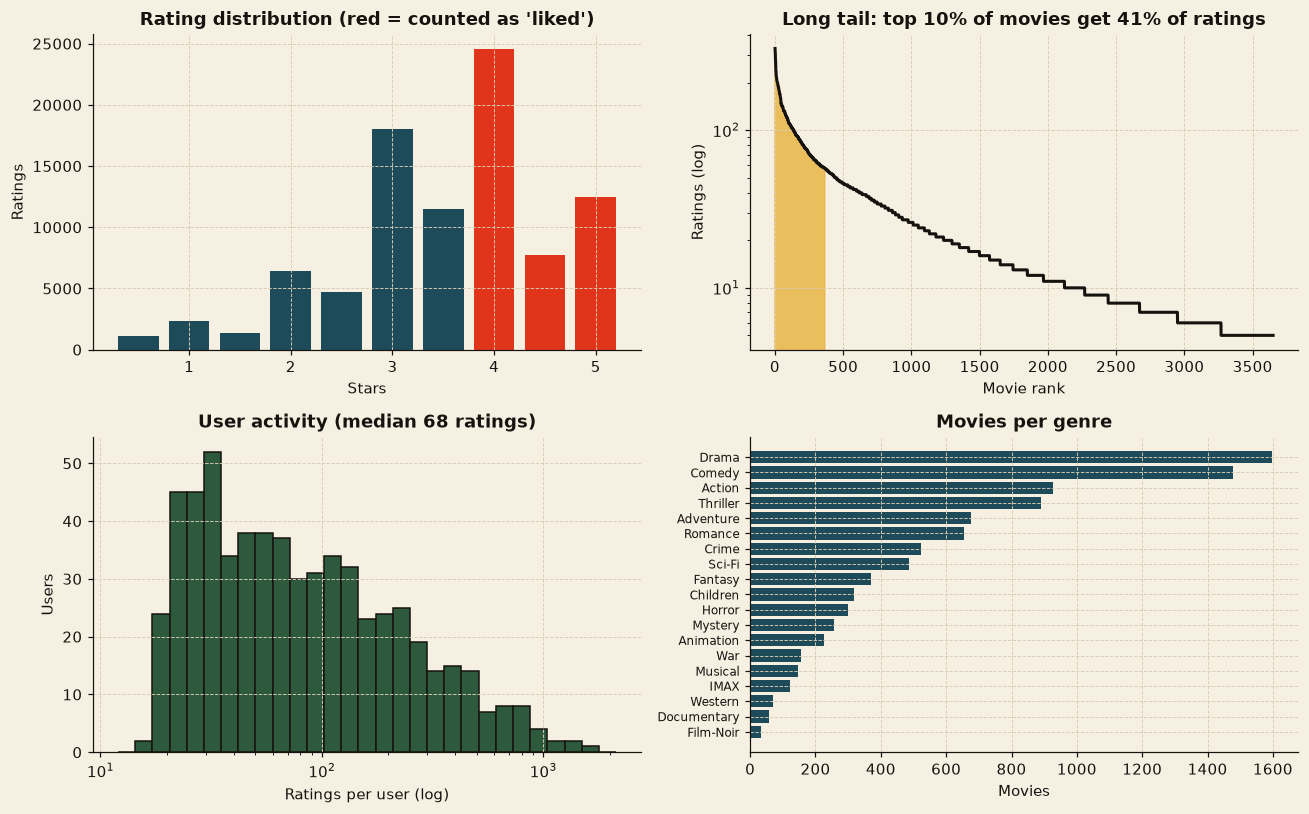

In [7]:
def plot_eda(data: Dataset) -> None:
    """Rating histogram, movie long tail, user activity and genre frequency."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

    stars, counts = np.unique(data.r_value, return_counts=True)
    axes[0, 0].bar(stars, counts, width=0.4, color=[PALETTE["red"] if s >= CONFIG.like_threshold else PALETTE["teal"] for s in stars])
    axes[0, 0].set(title="Rating distribution (red = counted as 'liked')", xlabel="Stars", ylabel="Ratings")

    per_movie = np.sort(np.bincount(data.r_item))[::-1]
    top_decile_share = per_movie[: len(per_movie) // 10].sum() / per_movie.sum()
    axes[0, 1].plot(np.arange(1, len(per_movie) + 1), per_movie, color=PALETTE["ink"], lw=2)
    axes[0, 1].fill_between(np.arange(1, len(per_movie) // 10 + 1), per_movie[: len(per_movie) // 10], color=PALETTE["mustard"], alpha=0.8)
    axes[0, 1].set(title=f"Long tail: top 10% of movies get {top_decile_share:.0%} of ratings", xlabel="Movie rank", ylabel="Ratings (log)", yscale="log")

    per_user = np.bincount(data.r_user)
    axes[1, 0].hist(per_user, bins=np.logspace(np.log10(per_user.min()), np.log10(per_user.max()), 30), color=PALETTE["green"], edgecolor=PALETTE["ink"])
    axes[1, 0].set(title=f"User activity (median {np.median(per_user):.0f} ratings)", xlabel="Ratings per user (log)", ylabel="Users", xscale="log")

    genre_counts: dict[str, int] = {}
    for genres in data.genres:
        for g in genres:
            genre_counts[g] = genre_counts.get(g, 0) + 1
    names, values = zip(*sorted(genre_counts.items(), key=lambda kv: kv[1]))
    axes[1, 1].barh(names, values, color=PALETTE["teal"])
    axes[1, 1].set(title="Movies per genre", xlabel="Movies")
    axes[1, 1].tick_params(axis="y", labelsize=8)

    fig.tight_layout()
    plt.show()


plot_eda(dataset)

### 2.4 Temporal train/test split

**The Goal:** hold out each user's **most recent 20%** of ratings as the test set.

**The Why:** a random split leaks the future: the model would learn from ratings made *after* the ones it is asked to predict, which inflates scores. A per-user temporal split mirrors production, where we know a user's past and must predict what they will enjoy next. Users keep at least 3 training ratings so that every evaluated user has a history to fold in.

| Parameter | Value | Meaning |
|---|---|---|
| `test_fraction` | 0.2 | Last 20% of each user's timeline |
| Minimum history | 3 ratings | Users with shorter histories stay entirely in train |
| Ground truth | test ratings ≥ 4★ | What a good recommender should surface |

In [8]:
train_mask, test_mask = temporal_split(dataset, test_frac=CONFIG.test_fraction)


def validate_split(data: Dataset, train: np.ndarray, test: np.ndarray) -> list[tuple[str, bool]]:
    """Check the split is disjoint, complete and leak-free in time.

    Parameters
    ----------
    data : Dataset
    train, test : np.ndarray of bool, shape (n_ratings,)

    Returns
    -------
    list of (str, bool)
    """
    no_future_leak = True
    for user in np.unique(data.r_user[test]):
        user_train_times = data.r_time[train & (data.r_user == user)]
        user_test_times = data.r_time[test & (data.r_user == user)]
        if user_train_times.max() > user_test_times.min():
            no_future_leak = False
            break
    test_share = test.sum() / len(test)
    return [
        ("Train and test are disjoint", not bool(np.any(train & test))),
        ("Every rating is in exactly one split", bool(np.all(train | test))),
        ("No training rating is newer than a test rating (per user)", no_future_leak),
        (f"Test share ≈ {CONFIG.test_fraction:.0%} (actual {test_share:.1%})", abs(test_share - CONFIG.test_fraction) < 0.03),
        ("Every test user keeps ≥ 3 training ratings",
         bool(np.bincount(data.r_user[train], minlength=data.n_users)[np.unique(data.r_user[test])].min() >= 3)),
    ]


split_checks = validate_split(dataset, train_mask, test_mask)
show_table([{"Check": n, "Status": "✅ pass" if ok else "❌ FAIL"} for n, ok in split_checks], title="Split validation")
assert all(ok for _, ok in split_checks)

train_seen = seen(dataset, train_mask)
test_liked = positives(dataset, test_mask, threshold=CONFIG.like_threshold)
evaluable_users = sum(1 for u in range(dataset.n_users) if test_liked[u] and train_seen[u])
show_table([
    {"Split": "Train", "Ratings": f"{train_mask.sum():,}", "Users": f"{len(np.unique(dataset.r_user[train_mask])):,}"},
    {"Split": "Test", "Ratings": f"{test_mask.sum():,}", "Users": f"{len(np.unique(dataset.r_user[test_mask])):,}"},
    {"Split": "Test likes (≥4★)", "Ratings": f"{sum(len(s) for s in test_liked):,}", "Users": f"{evaluable_users:,} evaluable"},
])

**Split validation**

| Check | Status |
|---|---|
| Train and test are disjoint | ✅ pass |
| Every rating is in exactly one split | ✅ pass |
| No training rating is newer than a test rating (per user) | ✅ pass |
| Test share ≈ 20% (actual 20.0%) | ✅ pass |
| Every test user keeps ≥ 3 training ratings | ✅ pass |

| Split | Ratings | Users |
|---|---|---|
| Train | 72,236 | 610 |
| Test | 18,038 | 610 |
| Test likes (≥4★) | 8,608 | 591 evaluable |

---
<a id="phase3"></a>
# 🏗️ Phase 3: Model Architecture & Compilation

This is not a neural network. It is a **two-tower factorisation** whose "layers" are closed-form matrix decompositions, so there are no epochs and no gradient descent. "Compiling" the model means computing the factorisations and checking their shapes and invariants.

### 3.1 The maths

**Collaborative view.** Centre every rating on a *shrunk* user mean, then take a rank-$k$ truncated SVD:

$$\tilde r_{ui} = r_{ui} - \frac{\sum_i r_{ui} + \lambda\,\mu}{n_u + \lambda}, \qquad \tilde R \approx U_k \Sigma_k V_k^\top, \qquad \mathbf{c}_i = \frac{(V_k \Sigma_k^{1/2})_i}{\lVert\cdot\rVert}$$

**Content view.** For each movie, build a bag of tokens from its genres (weight 3), user tags and tag words. Apply TF-IDF with sublinear term frequency, then LSA (a rank-32 SVD):

$$w_{t,i} = \bigl(1 + \log \text{tf}_{t,i}\bigr)\Bigl(\log\tfrac{1+N}{1+\text{df}_t} + 1\Bigr), \qquad \mathbf{t}_i = \frac{(U_{32}\Sigma_{32})_i}{\lVert\cdot\rVert}$$

**Hybrid fusion.** Concatenate the two views, weighted so that the dot product decomposes exactly:

$$\mathbf{h}_i = \bigl[\sqrt{\alpha}\,\mathbf{c}_i \,;\, \sqrt{1-\alpha}\,\mathbf{t}_i\bigr] \quad\Rightarrow\quad \mathbf{h}_i\!\cdot\!\mathbf{h}_j = \alpha\cos(\mathbf{c}_i,\mathbf{c}_j) + (1-\alpha)\cos(\mathbf{t}_i,\mathbf{t}_j)$$

**User fold-in and scoring.** A user is the normalised, weighted sum of the movies they rated ($+1$ for ≥4★, $-0.5$ for ≤2★). The final score adds a popularity prior $p_i \in [0,1]$:

$$\mathbf{u} = \frac{\sum_i w_{ui}\,\mathbf{h}_i}{\lVert\cdot\rVert}, \qquad \text{score}(u,i) = \mathbf{u}\cdot\mathbf{h}_i + \beta\,p_i$$

> 💡 **Why fold-in?** Users have **zero stored parameters**. A brand-new user who has just picked three favourite films in the onboarding quiz gets a taste vector instantly, with no retraining. The Node API runs exactly this arithmetic in ~1 ms.

**Key Parameters**

| Symbol | Name | Value / range | Role |
|---|---|---|---|
| $k$ | collaborative rank | 24 / 48 / 96 | Model capacity (tuned) |
| $\lambda$ | mean shrinkage | 10 | Stabilises light users' means |
| — | content rank | 32 | LSA topics |
| $\alpha$ | view weight | 0 → 1 | Collaborative vs content (tuned) |
| $\beta$ | popularity prior | 0 → 0.7 | Accuracy vs diversity (tuned) |

### 3.2 Build the components and display shapes & parameter counts

**The Goal:** materialise each "layer" on the **training split only**, then report its shape, the number of learned values and its memory footprint.

**The Why:** the shape table plays the role of `model.summary()` in deep learning. It makes the size of the deployable artifact explicit: what ships to the API is just the hybrid matrix plus two priors.

In [9]:
REFERENCE_COLLAB_DIMS = 48  # the production rank; the grid search in Phase 4 confirms it

collab_vectors = collaborative_factors(dataset, train_mask, k=REFERENCE_COLLAB_DIMS)
tfidf_matrix, vocabulary = tfidf(content_documents(dataset))
content_vectors = content_factors(dataset, k=CONFIG.content_dims)
reference_embeddings = hybrid(collab_vectors, content_vectors, alpha=0.9)
train_popularity = popularity_prior(dataset, train_mask)

train_ratings_matrix_nnz = int(train_mask.sum())
architecture = [
    {"Component": "Input: rating matrix R (train)", "Shape": f"{dataset.n_users} × {dataset.n_items}",
     "Learned values": "—", "Notes": f"{train_ratings_matrix_nnz:,} non-zeros ({train_ratings_matrix_nnz / (dataset.n_users * dataset.n_items):.2%})"},
    {"Component": "Collaborative SVD → item factors C", "Shape": f"{collab_vectors.shape[0]} × {collab_vectors.shape[1]}",
     "Learned values": f"{collab_vectors.size:,}", "Notes": "row-normalised V·Σ^½"},
    {"Component": "Input: TF-IDF matrix (genres + tags)", "Shape": f"{tfidf_matrix.shape[0]} × {tfidf_matrix.shape[1]}",
     "Learned values": f"{len(vocabulary):,} IDF weights", "Notes": f"{tfidf_matrix.nnz:,} non-zeros"},
    {"Component": "Content LSA → item factors T", "Shape": f"{content_vectors.shape[0]} × {content_vectors.shape[1]}",
     "Learned values": f"{content_vectors.size:,}", "Notes": "row-normalised U·Σ"},
    {"Component": "Hybrid embedding H = [√α·C ; √(1−α)·T]", "Shape": f"{reference_embeddings.shape[0]} × {reference_embeddings.shape[1]}",
     "Learned values": f"{reference_embeddings.size:,}", "Notes": f"float32 → {reference_embeddings.nbytes / 1024**2:.2f} MB (the shipped artifact)"},
    {"Component": "Popularity prior p", "Shape": f"{train_popularity.shape[0]}", "Learned values": f"{train_popularity.size:,}", "Notes": "log-count, scaled to [0, 1]"},
    {"Component": "User tower", "Shape": "fold-in", "Learned values": "0", "Notes": "computed per request, nothing stored"},
]
show_table(architecture, title="Model summary")
total_params = reference_embeddings.size + train_popularity.size
log.info("Deployable parameters: %s (%.2f MB)", f"{total_params:,}", (reference_embeddings.nbytes + train_popularity.nbytes) / 1024**2)

**Model summary**

| Component | Shape | Learned values | Notes |
|---|---|---|---|
| Input: rating matrix R (train) | 610 × 3650 | — | 72,236 non-zeros (3.24%) |
| Collaborative SVD → item factors C | 3650 × 48 | 175,200 | row-normalised V·Σ^½ |
| Input: TF-IDF matrix (genres + tags) | 3650 × 1062 | 1,062 IDF weights | 14,206 non-zeros |
| Content LSA → item factors T | 3650 × 32 | 116,800 | row-normalised U·Σ |
| Hybrid embedding H = [√α·C ; √(1−α)·T] | 3650 × 80 | 292,000 | float32 → 1.11 MB (the shipped artifact) |
| Popularity prior p | 3650 | 3,650 | log-count, scaled to [0, 1] |
| User tower | fold-in | 0 | computed per request, nothing stored |

16:55:54 | INFO    | Deployable parameters: 295,650 (1.13 MB)


### 3.3 Invariant checks and spectral diagnostics

**The Goal:** prove that the fusion identity holds numerically, and look at how much structure each SVD rank captures.

**The Why:** the identity $\mathbf{h}_i\cdot\mathbf{h}_j = \alpha\cos_c + (1-\alpha)\cos_t$ is what makes $\alpha$ interpretable. If it broke (for example, through a missing normalisation), the grid search would tune a meaningless knob. It holds for films that have **both** views. A film with no training ratings has an all-zero collaborative half, and the re-normalisation in `hybrid()` deliberately makes it fall back to its pure content vector. That is the cold-start path, and it is checked explicitly. The singular-value spectrum shows diminishing returns past a certain rank, which is the capacity trade-off we tune in Phase 4.

| Invariant | Value | Status |
|---|---|---|
| Fusion identity, max abs error (items with both views) | 8.67e-08 | ✅ |
| Cold items (no train ratings) fall back to content vector | 2 items: Paper Moon, 13 Hours | ✅ |
| All hybrid rows unit-length | [1.000000, 1.000000] | ✅ |
| No NaN / Inf in embeddings | True | ✅ |

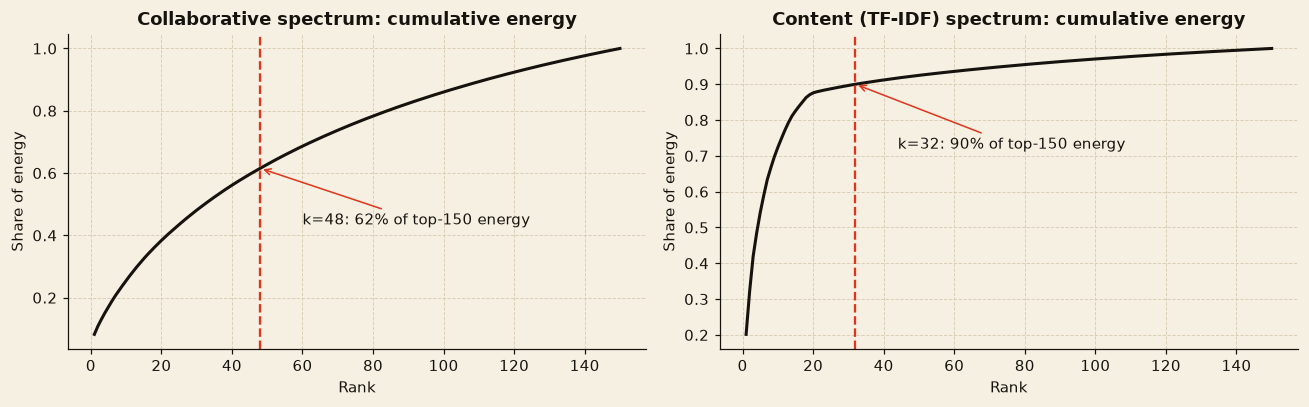

In [10]:
def check_fusion_identity(collab: np.ndarray, content: np.ndarray, alpha: float, sample_pairs: int = 2_000) -> float:
    """Return the max |h_i·h_j − (α cos_c + (1−α) cos_t)| over random pairs of items that have BOTH views."""
    rng = np.random.default_rng(CONFIG.seed)
    has_both = np.flatnonzero((np.linalg.norm(collab, axis=1) > 0.5) & (np.linalg.norm(content, axis=1) > 0.5))
    i, j = rng.choice(has_both, size=(2, sample_pairs))
    fused = hybrid(collab, content, alpha)
    lhs = np.einsum("nd,nd->n", fused[i], fused[j])
    rhs = alpha * np.einsum("nd,nd->n", collab[i], collab[j]) + (1 - alpha) * np.einsum("nd,nd->n", content[i], content[j])
    return float(np.abs(lhs - rhs).max())


identity_error = check_fusion_identity(collab_vectors, content_vectors, alpha=0.9)
norms = np.linalg.norm(reference_embeddings, axis=1)

# Films first rated in the test window have no training ratings → zero collaborative vector.
# By design the hybrid then falls back to the pure content vector (cold start).
cold_items = np.flatnonzero(np.linalg.norm(collab_vectors, axis=1) < 0.5)
collab_half = reference_embeddings[cold_items, :REFERENCE_COLLAB_DIMS]
content_half = reference_embeddings[cold_items, REFERENCE_COLLAB_DIMS:]
cold_fallback_ok = bool(np.allclose(collab_half, 0, atol=1e-6) and np.allclose(content_half, content_vectors[cold_items], atol=1e-5))
show_table([
    {"Invariant": "Fusion identity, max abs error (items with both views)", "Value": f"{identity_error:.2e}", "Status": "✅" if identity_error < 1e-5 else "❌"},
    {"Invariant": "Cold items (no train ratings) fall back to content vector",
     "Value": f"{len(cold_items)} items: " + ", ".join(dataset.titles[i] for i in cold_items[:3]), "Status": "✅" if cold_fallback_ok else "❌"},
    {"Invariant": "All hybrid rows unit-length", "Value": f"[{norms.min():.6f}, {norms.max():.6f}]", "Status": "✅" if np.allclose(norms, 1, atol=1e-4) else "❌"},
    {"Invariant": "No NaN / Inf in embeddings", "Value": str(bool(np.isfinite(reference_embeddings).all())), "Status": "✅" if np.isfinite(reference_embeddings).all() else "❌"},
])
assert identity_error < 1e-5 and cold_fallback_ok and np.allclose(norms, 1, atol=1e-4)


def centred_rating_matrix(data: Dataset, mask: np.ndarray, shrink: float = 10.0) -> csr_matrix:
    """Diagnostic copy of the centring step (mirrors ``collaborative_factors``) used to plot the spectrum."""
    users, items, ratings = data.r_user[mask], data.r_item[mask], data.r_value[mask].astype(np.float64)
    user_mean = (np.bincount(users, weights=ratings, minlength=data.n_users) + shrink * ratings.mean()) / (
        np.bincount(users, minlength=data.n_users) + shrink)
    return csr_matrix((ratings - user_mean[users], (users, items)), shape=(data.n_users, data.n_items))


collab_spectrum = np.sort(svds(centred_rating_matrix(dataset, train_mask), k=150, random_state=0)[1])[::-1]
content_spectrum = np.sort(svds(tfidf_matrix, k=150, random_state=0)[1])[::-1]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for axis, spectrum, name, chosen in [(ax[0], collab_spectrum, "Collaborative", REFERENCE_COLLAB_DIMS),
                                     (ax[1], content_spectrum, "Content (TF-IDF)", CONFIG.content_dims)]:
    energy = np.cumsum(spectrum**2) / np.sum(spectrum**2)
    axis.plot(np.arange(1, len(energy) + 1), energy, color=PALETTE["ink"], lw=2)
    axis.axvline(chosen, color=PALETTE["red"], ls="--", lw=1.5)
    axis.annotate(f"k={chosen}: {energy[chosen - 1]:.0%} of top-150 energy", (chosen, energy[chosen - 1]),
                  xytext=(chosen + 12, energy[chosen - 1] - 0.18), arrowprops={"arrowstyle": "->", "color": PALETTE["red"]})
    axis.set(title=f"{name} spectrum: cumulative energy", xlabel="Rank", ylabel="Share of energy")
fig.tight_layout()
plt.show()

---
<a id="phase4"></a>
# 🚀 Phase 4: Training Pipeline

### 4.1 Experiment tracking & checkpointing

**The Goal:** run every configuration, log it, and persist each result **as soon as it finishes**.

**The Why:** a JSON-Lines checkpoint named after the config fingerprint makes the search **resumable**: re-running the notebook skips trials already on disk. It is also auditable, since every number in this notebook can be traced back to a logged trial. The lightweight tracker below mirrors what MLflow or Weights & Biases provide, without a server.

| Field logged per trial | Description |
|---|---|
| `collab_dims`, `alpha`, `beta` | Hyperparameters |
| `recall@10`, `ndcg@10`, `hit_rate@10` | Ranking quality on the temporal hold-out |
| `coverage` | Share of the catalogue recommended to at least one user |
| `seconds` | Wall-clock cost of the trial |

In [11]:
@dataclass
class Trial:
    """One evaluated hyperparameter configuration."""

    collab_dims: int
    alpha: float
    beta: float
    metrics: dict[str, float]
    seconds: float

    @property
    def key(self) -> tuple[int, float, float]:
        return (self.collab_dims, self.alpha, self.beta)


class ExperimentTracker:
    """Append-only JSONL experiment log that doubles as a resumable checkpoint.

    Parameters
    ----------
    path : Path
        Checkpoint file; existing trials are loaded on construction.
    """

    def __init__(self, path: Path) -> None:
        self.path = path
        self.trials: dict[tuple[int, float, float], Trial] = {}
        if path.exists():
            for line in path.read_text(encoding="utf-8").splitlines():
                trial = Trial(**json.loads(line))
                self.trials[trial.key] = trial
            log.info("Resumed %d trials from checkpoint %s", len(self.trials), path.name)

    def has(self, key: tuple[int, float, float]) -> bool:
        return key in self.trials

    def record(self, trial: Trial) -> None:
        """Store a trial in memory and append it to disk immediately (crash-safe)."""
        self.trials[trial.key] = trial
        with self.path.open("a", encoding="utf-8") as fh:
            fh.write(json.dumps(asdict(trial)) + "\n")


tracker = ExperimentTracker(CONFIG.artifact_dir / f"experiments_{CONFIG.fingerprint()}.jsonl")

### 4.2 Grid search

**The Goal:** evaluate 3 ranks × 6 α × 7 β = **126 configurations** on the temporal hold-out.

**The Why:** the search is cheap, because the expensive SVD is computed once per rank, every $(\alpha, \beta)$ pair reuses it, and $\beta$ only shifts scores. That makes an exhaustive grid affordable and more trustworthy than a random search at this size. The popularity prior uses **training counts only**, so no test information leaks.

In [12]:
def run_grid_search(data: Dataset, cfg: RunConfig, tracker: ExperimentTracker) -> None:
    """Evaluate every (collab_dims, alpha, beta) combination, logging and checkpointing each trial."""
    total = len(cfg.collab_dims_grid) * len(cfg.alpha_grid) * len(cfg.beta_grid)
    started = time.perf_counter()
    for collab_dims in cfg.collab_dims_grid:
        pending = [(a, b) for a in cfg.alpha_grid for b in cfg.beta_grid if not tracker.has((collab_dims, a, b))]
        if not pending:
            log.info("collab_dims=%-3d all %d trials already checkpointed, skipping", collab_dims, len(cfg.alpha_grid) * len(cfg.beta_grid))
            continue
        fit_start = time.perf_counter()
        collab = collaborative_factors(data, train_mask, k=collab_dims)
        log.info("collab_dims=%-3d SVD fitted in %.2fs", collab_dims, time.perf_counter() - fit_start)
        for alpha in cfg.alpha_grid:
            embeddings = hybrid(collab, content_vectors, alpha)
            base_scores = user_profiles(data, train_mask, embeddings) @ embeddings.T
            for beta in cfg.beta_grid:
                if tracker.has((collab_dims, alpha, beta)):
                    continue
                trial_start = time.perf_counter()
                metrics = rank_metrics(base_scores + beta * train_popularity, train_seen, test_liked, k=cfg.top_k)
                tracker.record(Trial(collab_dims, alpha, beta, metrics, round(time.perf_counter() - trial_start, 4)))
        best_so_far = max((t for t in tracker.trials.values() if t.collab_dims == collab_dims), key=lambda t: t.metrics["ndcg@10"])
        log.info("collab_dims=%-3d done | best NDCG@10 %.4f (α=%.1f, β=%.1f, coverage %.1f%%)", collab_dims,
                 best_so_far.metrics["ndcg@10"], best_so_far.alpha, best_so_far.beta, 100 * best_so_far.metrics["coverage"])
    log.info("Grid search complete: %d/%d trials in %.1fs", len(tracker.trials), total, time.perf_counter() - started)


run_grid_search(dataset, CONFIG, tracker)

16:55:55 | INFO    | collab_dims=24  SVD fitted in 0.02s


16:55:56 | INFO    | collab_dims=24  done | best NDCG@10 0.1104 (α=0.8, β=0.7, coverage 15.4%)


16:55:56 | INFO    | collab_dims=48  SVD fitted in 0.04s


16:55:57 | INFO    | collab_dims=48  done | best NDCG@10 0.1174 (α=0.9, β=0.7, coverage 14.0%)


16:55:57 | INFO    | collab_dims=96  SVD fitted in 0.10s


16:55:58 | INFO    | collab_dims=96  done | best NDCG@10 0.1163 (α=0.9, β=0.7, coverage 11.8%)


16:55:58 | INFO    | Grid search complete: 126/126 trials in 3.0s


### 4.3 Model selection with a diversity constraint

**The Goal:** pick the configuration with the best NDCG@10 **among those that recommend at least 20% of the catalogue**.

**The Why:** on a temporal split, popular films are disproportionately what users rate next, so raising $\beta$ keeps nudging accuracy up while coverage collapses toward "everyone gets the same 50 blockbusters". That is a worse product even though it scores better offline. A coverage floor encodes the product requirement directly in the selection rule.

In [13]:
def select_best(trials: list[Trial], min_coverage: float) -> tuple[Trial, Trial]:
    """Return (best trial satisfying the coverage floor, best trial overall)."""
    eligible = [t for t in trials if t.metrics["coverage"] >= min_coverage]
    assert eligible, "No configuration satisfies the coverage constraint"
    by_ndcg = lambda t: t.metrics["ndcg@10"]  # noqa: E731
    return max(eligible, key=by_ndcg), max(trials, key=by_ndcg)


all_trials = list(tracker.trials.values())
best_trial, unconstrained_trial = select_best(all_trials, CONFIG.min_coverage)

leaderboard = sorted((t for t in all_trials if t.metrics["coverage"] >= CONFIG.min_coverage), key=lambda t: -t.metrics["ndcg@10"])[:8]
show_table([{"Rank": i + 1, "collab_dims": t.collab_dims, "α": t.alpha, "β": t.beta, "NDCG@10": t.metrics["ndcg@10"],
             "Recall@10": t.metrics["recall@10"], "Coverage": f"{t.metrics['coverage']:.1%}"} for i, t in enumerate(leaderboard)],
           title=f"Leaderboard (coverage ≥ {CONFIG.min_coverage:.0%})")
display(Markdown(
    f"> 🏆 **Selected:** `collab_dims={best_trial.collab_dims}, α={best_trial.alpha}, β={best_trial.beta}` "
    f"with NDCG@10 **{best_trial.metrics['ndcg@10']:.4f}** at **{best_trial.metrics['coverage']:.1%}** coverage.\n>\n"
    f"> For comparison, the unconstrained optimum (β={unconstrained_trial.beta}) reaches NDCG@10 {unconstrained_trial.metrics['ndcg@10']:.4f} "
    f"but only {unconstrained_trial.metrics['coverage']:.1%} coverage: "
    f"**+{unconstrained_trial.metrics['ndcg@10'] / best_trial.metrics['ndcg@10'] - 1:.0%} accuracy for "
    f"{1 - unconstrained_trial.metrics['coverage'] / best_trial.metrics['coverage']:.0%} less of the catalogue**."))

**Leaderboard (coverage ≥ 20%)**

| Rank | collab_dims | α | β | NDCG@10 | Recall@10 | Coverage |
|---|---|---|---|---|---|---|
| 1 | 48 | 0.9000 | 0.4000 | 0.1086 | 0.1156 | 22.6% |
| 2 | 96 | 0.9000 | 0.4000 | 0.1086 | 0.1127 | 21.2% |
| 3 | 96 | 0.8000 | 0.4000 | 0.1082 | 0.1141 | 20.0% |
| 4 | 48 | 0.8000 | 0.4000 | 0.1071 | 0.1139 | 21.3% |
| 5 | 48 | 1.0000 | 0.5000 | 0.1070 | 0.1126 | 20.8% |
| 6 | 96 | 1.0000 | 0.4000 | 0.1067 | 0.1100 | 23.3% |
| 7 | 48 | 1.0000 | 0.4000 | 0.1033 | 0.1076 | 24.2% |
| 8 | 48 | 0.7000 | 0.4000 | 0.1028 | 0.1092 | 20.7% |

> 🏆 **Selected:** `collab_dims=48, α=0.9, β=0.4` with NDCG@10 **0.1086** at **22.6%** coverage.
>
> For comparison, the unconstrained optimum (β=0.7) reaches NDCG@10 0.1174 but only 14.0% coverage: **+8% accuracy for 38% less of the catalogue**.

### 4.4 Capacity curve (the "training curve" of a closed-form model)

**The Goal:** show how validation quality changes with model capacity, the role a loss/accuracy-vs-epoch curve plays for neural nets.

**The Why:** a truncated SVD is solved exactly, so there are no epochs to plot. The honest analogue is **validation NDCG vs rank $k$**. Too low a rank underfits (it can't separate tastes); too high a rank starts fitting noise in the sparse matrix.

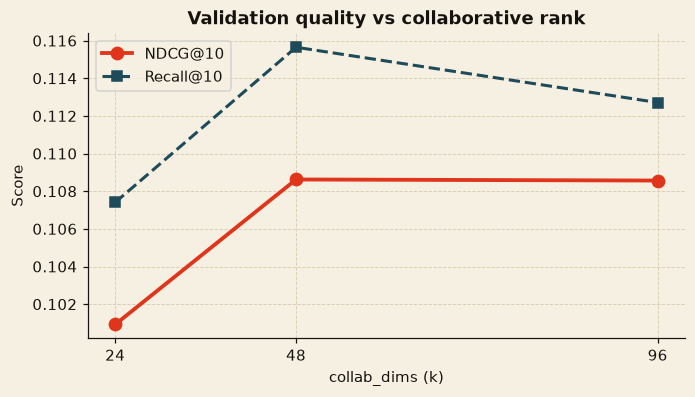

| collab_dims | NDCG@10 | Recall@10 | Coverage | α | β |
|---|---|---|---|---|---|
| 24 | 0.1009 | 0.1074 | 0.2115 | 0.9000 | 0.5000 |
| 48 | 0.1086 | 0.1156 | 0.2263 | 0.9000 | 0.4000 |
| 96 | 0.1086 | 0.1127 | 0.2115 | 0.9000 | 0.4000 |

In [14]:
def capacity_curve(trials: list[Trial], min_coverage: float) -> list[dict]:
    """Best eligible validation metrics for each collaborative rank."""
    rows = []
    for dims in sorted({t.collab_dims for t in trials}):
        group = [t for t in trials if t.collab_dims == dims and t.metrics["coverage"] >= min_coverage]
        best = max(group, key=lambda t: t.metrics["ndcg@10"])
        rows.append({"collab_dims": dims, "NDCG@10": best.metrics["ndcg@10"], "Recall@10": best.metrics["recall@10"],
                     "Coverage": best.metrics["coverage"], "α": best.alpha, "β": best.beta})
    return rows


capacity = capacity_curve(all_trials, CONFIG.min_coverage)
fig, ax = plt.subplots(figsize=(7, 3.6))
dims = [r["collab_dims"] for r in capacity]
ax.plot(dims, [r["NDCG@10"] for r in capacity], "o-", color=PALETTE["red"], lw=2.5, ms=8, label="NDCG@10")
ax.plot(dims, [r["Recall@10"] for r in capacity], "s--", color=PALETTE["teal"], lw=2, ms=7, label="Recall@10")
ax.set(title="Validation quality vs collaborative rank", xlabel="collab_dims (k)", ylabel="Score", xticks=dims)
ax.legend()
plt.show()
show_table(capacity, floatfmt="{:.4f}")

### 4.5 Final refit on all data & export (checkpoint)

**The Goal:** retrain with the selected hyperparameters on **100%** of the ratings, export the serving artifact, and fingerprint it.

**The Why:** the hold-out has done its job (choosing hyperparameters), so the production model should learn from every rating, including the most recent ones. The export reuses `train.export`, the exact function the production pipeline uses. The SHA-256 manifest lets the API, CI or a reviewer verify which model is deployed.

| Parameter | Value |
|---|---|
| Output | `ml/artifacts/model/` (or `backend/model/` if `export_to_backend=True`) |
| Files | `model.json` (metadata, priors, metrics) · `embeddings.bin` (float32, row-major) · `manifest.json` (hashes) |

In [15]:
from train import export  # the production exporter, shared with `python train.py`  # noqa: E402


def sha256_file(path: Path) -> str:
    """Hex SHA-256 of a file."""
    return hashlib.sha256(path.read_bytes()).hexdigest()


def baseline_metrics(collab_dims: int, alpha: float, beta: float) -> dict[str, float]:
    """Look up a logged trial's metrics (used for the content-only / collab-only baselines)."""
    return tracker.trials[(collab_dims, alpha, beta)].metrics


popularity_only_metrics = rank_metrics(np.tile(train_popularity, (dataset.n_users, 1)), train_seen, test_liked, k=CONFIG.top_k)
report = {
    "split": f"per-user temporal {1 - CONFIG.test_fraction:.0%}/{CONFIG.test_fraction:.0%}, positives = rating >= {CONFIG.like_threshold:g}",
    "selection": f"max NDCG@10 with catalogue coverage >= {CONFIG.min_coverage}",
    "best": {"params": {"alpha": best_trial.alpha, "beta": best_trial.beta}, "metrics": best_trial.metrics},
    "baselines": {
        "popularity": popularity_only_metrics,
        "contentOnly": baseline_metrics(best_trial.collab_dims, 0.0, best_trial.beta),
        "collabOnly": baseline_metrics(best_trial.collab_dims, 1.0, best_trial.beta),
    },
}

export_dir = (ML_ROOT.parent / "backend" / "model") if CONFIG.export_to_backend else (CONFIG.artifact_dir / "model")
fit_start = time.perf_counter()
export(dataset, export_dir, best_trial.alpha, best_trial.beta, best_trial.collab_dims, CONFIG.content_dims, report)
manifest = {
    "config_fingerprint": CONFIG.fingerprint(),
    "params": {"collab_dims": best_trial.collab_dims, "content_dims": CONFIG.content_dims, "alpha": best_trial.alpha, "beta": best_trial.beta},
    "files": {p.name: {"bytes": p.stat().st_size, "sha256": sha256_file(p)} for p in sorted(export_dir.glob("*")) if p.name != "manifest.json"},
}
(export_dir / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
log.info("Refit + export finished in %.2fs → %s", time.perf_counter() - fit_start, export_dir)

# Reload the checkpoint exactly as the API does and verify it.
exported_meta = json.loads((export_dir / "model.json").read_text(encoding="utf-8"))
exported = np.fromfile(export_dir / "embeddings.bin", dtype="<f4").reshape(exported_meta["count"], exported_meta["dim"])
assert np.allclose(np.linalg.norm(exported, axis=1), 1, atol=1e-4)
production_file = ML_ROOT.parent / "backend" / "model" / "embeddings.bin"
show_table([{"File": name, "Size (KB)": f"{info['bytes'] / 1024:,.0f}", "SHA-256": info["sha256"][:16] + "…"} for name, info in manifest["files"].items()],
           title=f"Exported artifact: {exported.shape[0]:,} movies × {exported.shape[1]} dims")
if production_file.exists():
    same = sha256_file(production_file) == manifest["files"]["embeddings.bin"]["sha256"]
    display(Markdown(f"> {'✅' if same else 'ℹ️'} Embeddings are **{'byte-identical to' if same else 'different from'}** the model currently deployed in `backend/model/`."))

Exported 3650 movies x 80 dims -> C:\Users\Asus\Documents\project\move recommendation system\ml\artifacts\model
16:55:58 | INFO    | Refit + export finished in 0.11s → C:\Users\Asus\Documents\project\move recommendation system\ml\artifacts\model


**Exported artifact: 3,650 movies × 80 dims**

| File | Size (KB) | SHA-256 |
|---|---|---|
| embeddings.bin | 1,141 | 836fa58304560e94… |
| model.json | 673 | 313a445743e62708… |

> ✅ Embeddings are **byte-identical to** the model currently deployed in `backend/model/`.

---
<a id="phase5"></a>
# 📊 Phase 5: Comprehensive Evaluation

All numbers below come from the **temporal hold-out**. The model selected in Phase 4 is rebuilt on the training split so that it is evaluated on ratings it has never seen.

### 5.1 Headline metrics vs baselines

**The Goal:** compare the selected hybrid against three meaningful baselines.

**The Why:** a recommender is only useful if it beats "show everyone the popular films" (**popularity**), and the hybrid is only justified if it beats each of its halves alone (**content-only**, $\alpha=0$; **collaborative-only**, $\alpha=1$).

| Metric | Definition |
|---|---|
| Recall@10 | share of a user's future likes found in their top 10 (capped at 10) |
| NDCG@10 | like recall, but hits ranked higher count more (log₂ discount) |
| Hit rate@10 | share of users with at least one future like in their top 10 |
| Coverage | share of the catalogue recommended to anyone |

In [16]:
def build_scores(collab_dims: int, alpha: float, beta: float) -> np.ndarray:
    """(n_users × n_items) hold-out score matrix for one configuration (trained on the train split only)."""
    embeddings = hybrid(collaborative_factors(dataset, train_mask, k=collab_dims), content_vectors, alpha)
    return user_profiles(dataset, train_mask, embeddings) @ embeddings.T + beta * train_popularity


models: dict[str, np.ndarray] = {
    "Popularity": np.tile(train_popularity, (dataset.n_users, 1)),
    "Content-only (α=0)": build_scores(best_trial.collab_dims, 0.0, best_trial.beta),
    "Collaborative-only (α=1)": build_scores(best_trial.collab_dims, 1.0, best_trial.beta),
    f"Hybrid (α={best_trial.alpha}, β={best_trial.beta})": build_scores(best_trial.collab_dims, best_trial.alpha, best_trial.beta),
}
results = {name: rank_metrics(scores, train_seen, test_liked, k=CONFIG.top_k) for name, scores in models.items()}
pop_ndcg = results["Popularity"]["ndcg@10"]
show_table([{"Model": name, "Recall@10": m["recall@10"], "NDCG@10": m["ndcg@10"], "Hit rate@10": m["hit_rate@10"],
             "Coverage": f"{m['coverage']:.1%}", "NDCG lift vs popularity": f"{m['ndcg@10'] / pop_ndcg - 1:+.0%}"}
            for name, m in results.items()], title=f"Hold-out results ({results['Popularity']['users']} users)")

**Hold-out results (591 users)**

| Model | Recall@10 | NDCG@10 | Hit rate@10 | Coverage | NDCG lift vs popularity |
|---|---|---|---|---|---|
| Popularity | 0.0747 | 0.0761 | 0.3232 | 2.6% | +0% |
| Content-only (α=0) | 0.0488 | 0.0445 | 0.2572 | 18.2% | -41% |
| Collaborative-only (α=1) | 0.1076 | 0.1033 | 0.4349 | 24.2% | +36% |
| Hybrid (α=0.9, β=0.4) | 0.1156 | 0.1086 | 0.4416 | 22.6% | +43% |

### 5.2 Hyperparameter landscape & the accuracy–diversity trade-off

**The Goal:** visualise *why* the selected point was chosen.

**The Why:** the heatmap shows NDCG across $(\alpha, \beta)$, with configurations that fail the coverage floor marked ✕. The scatter shows every trial in accuracy–coverage space. The chosen model sits on the efficient frontier, right at the coverage floor.

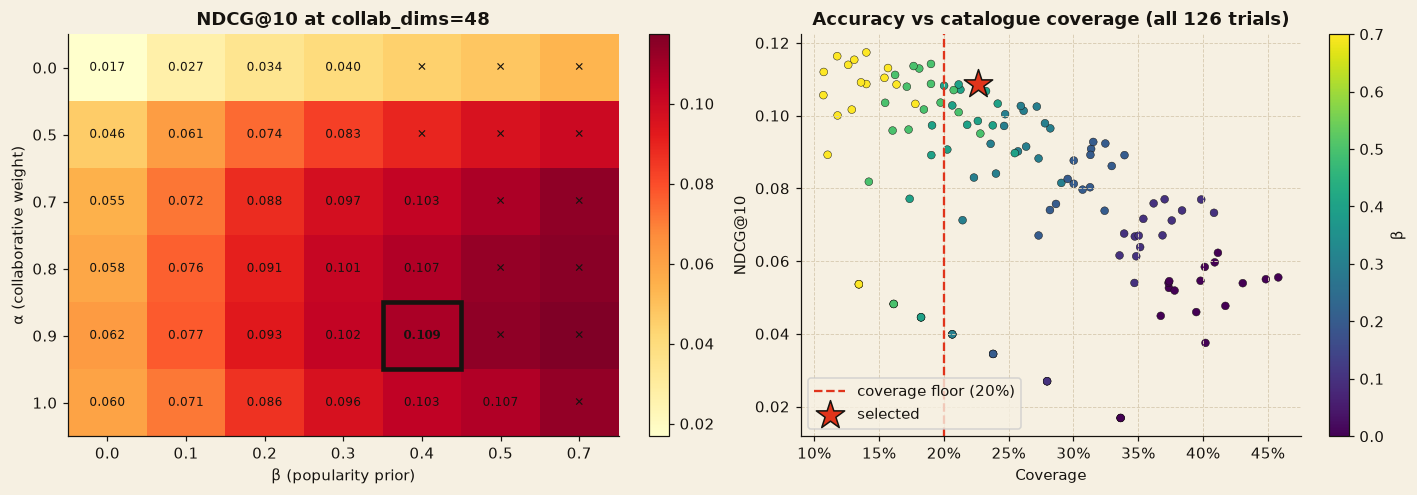

In [17]:
alphas, betas = list(CONFIG.alpha_grid), list(CONFIG.beta_grid)
grid = np.array([[tracker.trials[(best_trial.collab_dims, a, b)].metrics["ndcg@10"] for b in betas] for a in alphas])
coverage_grid = np.array([[tracker.trials[(best_trial.collab_dims, a, b)].metrics["coverage"] for b in betas] for a in alphas])

fig, (ax_heat, ax_front) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
image = ax_heat.imshow(grid, cmap="YlOrRd", aspect="auto")
ax_heat.set(xticks=range(len(betas)), xticklabels=betas, yticks=range(len(alphas)), yticklabels=alphas,
            xlabel="β (popularity prior)", ylabel="α (collaborative weight)", title=f"NDCG@10 at collab_dims={best_trial.collab_dims}")
ax_heat.grid(False)
for i, a in enumerate(alphas):
    for j, b in enumerate(betas):
        failing = coverage_grid[i, j] < CONFIG.min_coverage
        chosen = (a, b) == (best_trial.alpha, best_trial.beta)
        ax_heat.text(j, i, "✕" if failing else f"{grid[i, j]:.3f}", ha="center", va="center", fontsize=8,
                     color=PALETTE["ink"], fontweight="bold" if chosen else "normal")
        if chosen:
            ax_heat.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=PALETTE["ink"], lw=3))
fig.colorbar(image, ax=ax_heat, fraction=0.04)

coverage = np.array([t.metrics["coverage"] for t in all_trials])
ndcg = np.array([t.metrics["ndcg@10"] for t in all_trials])
scatter = ax_front.scatter(coverage, ndcg, c=[t.beta for t in all_trials], cmap="viridis", s=26, edgecolor=PALETTE["ink"], lw=0.3)
ax_front.axvline(CONFIG.min_coverage, color=PALETTE["red"], ls="--", lw=1.5, label=f"coverage floor ({CONFIG.min_coverage:.0%})")
ax_front.scatter([best_trial.metrics["coverage"]], [best_trial.metrics["ndcg@10"]], marker="*", s=380, color=PALETTE["red"], edgecolor=PALETTE["ink"], zorder=5, label="selected")
ax_front.set(title="Accuracy vs catalogue coverage (all 126 trials)", xlabel="Coverage", ylabel="NDCG@10")
ax_front.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.colorbar(scatter, ax=ax_front, fraction=0.04, label="β")
ax_front.legend(loc="lower left")
fig.tight_layout()
plt.show()

### 5.3 Recall@K and NDCG@K curves

**The Goal:** look beyond a single cut-off. How does each model behave from K = 1 to 50?

**The Why:** the app shows rows of 16–20 films, so K≈20 matters as much as K=10. A model that wins only at one K is fragile; curves that dominate across all K mean a robust improvement.

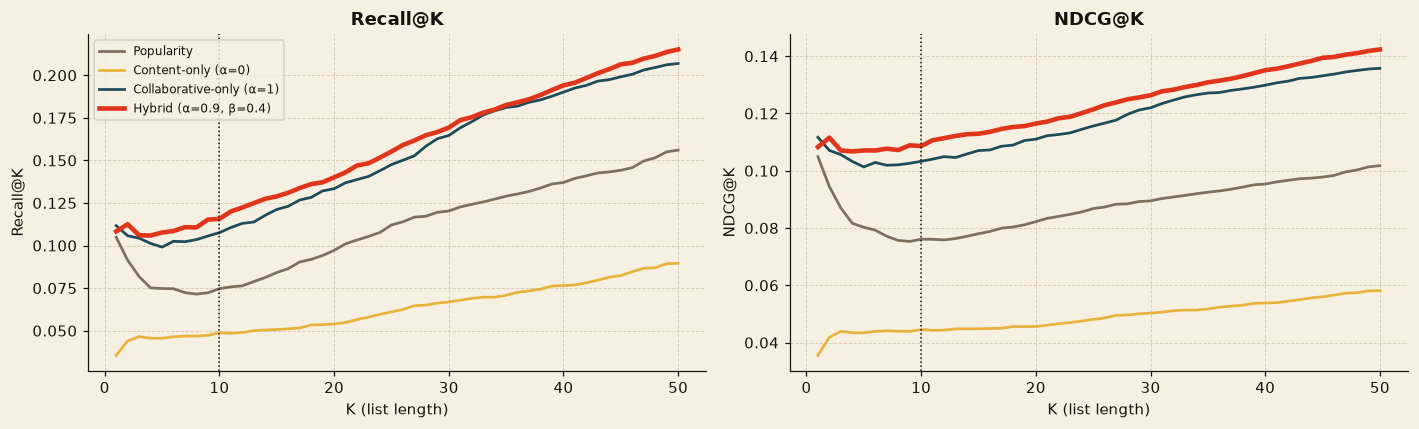

In [18]:
def ranking_curves(scores: np.ndarray, max_k: int = 50) -> dict[str, np.ndarray]:
    """Mean Recall@K, Precision@K and NDCG@K for K = 1..max_k (one ranking pass per user)."""
    discounts = 1.0 / np.log2(np.arange(2, max_k + 2))
    recall, precision, ndcg_values = [], [], []
    for user in range(scores.shape[0]):
        truth, history = test_liked[user], train_seen[user]
        if not truth or not history:
            continue
        user_scores = scores[user].copy()
        user_scores[list(history)] = -np.inf
        top = np.argpartition(-user_scores, max_k)[:max_k]
        top = top[np.argsort(-user_scores[top])]
        hits = np.isin(top, list(truth)).astype(float)
        cumulative_hits = np.cumsum(hits)
        ks = np.arange(1, max_k + 1)
        recall.append(cumulative_hits / np.minimum(ks, len(truth)))
        precision.append(cumulative_hits / ks)
        ideal = np.cumsum(discounts * (ks <= len(truth)))
        ndcg_values.append(np.cumsum(hits * discounts) / ideal)
    return {"recall": np.mean(recall, axis=0), "precision": np.mean(precision, axis=0), "ndcg": np.mean(ndcg_values, axis=0)}


curves = {name: ranking_curves(scores) for name, scores in models.items()}
colors = [PALETTE["muted"], PALETTE["mustard"], PALETTE["teal"], PALETTE["red"]]
ks = np.arange(1, 51)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (name, curve), color in zip(curves.items(), colors):
    lw = 3 if name.startswith("Hybrid") else 1.8
    axes[0].plot(ks, curve["recall"], color=color, lw=lw, label=name)
    axes[1].plot(ks, curve["ndcg"], color=color, lw=lw, label=name)
for axis, metric in zip(axes, ["Recall@K", "NDCG@K"]):
    axis.axvline(CONFIG.top_k, color=PALETTE["ink"], ls=":", lw=1)
    axis.set(title=metric, xlabel="K (list length)", ylabel=metric)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

### 5.4 Confusion matrix & classification report @K=10

**The Goal:** view the top-10 list as a binary classifier ("recommend" vs "don't recommend") over every candidate film, and score it against "the user later liked it".

**The Why:** this frames ranking quality in familiar classification terms. It also shows clearly why **accuracy is meaningless for recommenders**: true negatives (films neither recommended nor liked) dominate so heavily that a model recommending nothing would still score ~99.9% accuracy. Precision and recall on the *relevant* class are what matter.

| Cell | Meaning |
|---|---|
| TP | recommended, and the user later liked it |
| FP | recommended, but not (yet) liked; often simply unseen, so this is a pessimistic count |
| FN | liked later, but not in the top 10 |
| TN | neither recommended nor liked |

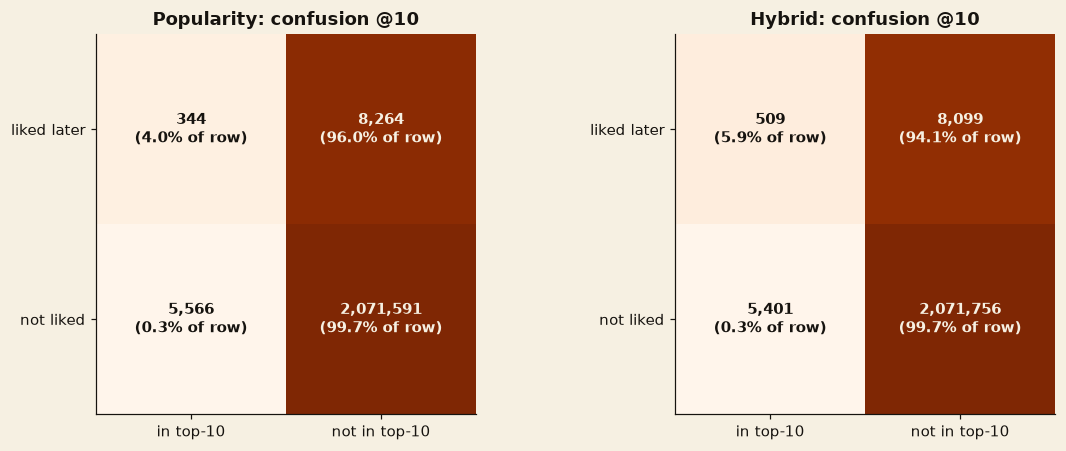

**Classification report @10: Hybrid (α=0.9, β=0.4)**

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| liked (relevant) | 0.0861 | 0.0591 | 0.0701 | 8,608 |
| not liked | 0.9961 | 0.9974 | 0.9968 | 2,077,157 |
| macro avg | 0.5411 | 0.5283 | 0.5334 | 2,085,765 |
| accuracy ⚠️ |  |  | 0.9935 | 2,085,765 |

In [19]:
def confusion_at_k(scores: np.ndarray, k: int) -> dict[str, int]:
    """Aggregate TP/FP/FN/TN over evaluable users for a top-k recommendation list."""
    tp = fp = fn = tn = 0
    for user in range(scores.shape[0]):
        truth, history = test_liked[user], train_seen[user]
        if not truth or not history:
            continue
        user_scores = scores[user].copy()
        user_scores[list(history)] = -np.inf
        recommended = set(np.argpartition(-user_scores, k)[:k].tolist())
        candidates = dataset.n_items - len(history)
        user_tp = len(recommended & truth)
        tp += user_tp
        fp += k - user_tp
        fn += len(truth) - user_tp
        tn += candidates - k - (len(truth) - user_tp)
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn}


def classification_report(cm: dict[str, int]) -> list[dict]:
    """sklearn-style precision / recall / F1 / support for both classes plus macro average and accuracy."""
    def prf(tp: int, fp: int, fn: int) -> tuple[float, float, float]:
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        return p, r, (2 * p * r / (p + r) if p + r else 0.0)

    pos = prf(cm["TP"], cm["FP"], cm["FN"])
    neg = prf(cm["TN"], cm["FN"], cm["FP"])
    total = sum(cm.values())
    return [
        {"Class": "liked (relevant)", "Precision": pos[0], "Recall": pos[1], "F1": pos[2], "Support": f"{cm['TP'] + cm['FN']:,}"},
        {"Class": "not liked", "Precision": neg[0], "Recall": neg[1], "F1": neg[2], "Support": f"{cm['TN'] + cm['FP']:,}"},
        {"Class": "macro avg", "Precision": (pos[0] + neg[0]) / 2, "Recall": (pos[1] + neg[1]) / 2, "F1": (pos[2] + neg[2]) / 2, "Support": f"{total:,}"},
        {"Class": "accuracy ⚠️", "Precision": "", "Recall": "", "F1": (cm["TP"] + cm["TN"]) / total, "Support": f"{total:,}"},
    ]


hybrid_name = next(n for n in models if n.startswith("Hybrid"))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for axis, name in zip(axes, ["Popularity", hybrid_name]):
    cm = confusion_at_k(models[name], CONFIG.top_k)
    matrix = np.array([[cm["TP"], cm["FN"]], [cm["FP"], cm["TN"]]])
    row_share = matrix / matrix.sum(axis=1, keepdims=True)
    axis.imshow(row_share, cmap="Oranges", vmin=0, vmax=1)
    axis.grid(False)
    for (i, j), value in np.ndenumerate(matrix):
        axis.text(j, i, f"{value:,}\n({row_share[i, j]:.1%} of row)", ha="center", va="center", fontsize=10, fontweight="bold",
                  color=PALETTE["paper"] if row_share[i, j] > 0.5 else PALETTE["ink"])
    axis.set(xticks=[0, 1], xticklabels=["in top-10", "not in top-10"], yticks=[0, 1], yticklabels=["liked later", "not liked"],
             title=f"{name.split(' (')[0]}: confusion @10")
    if name == hybrid_name:
        hybrid_cm = cm
fig.tight_layout()
plt.show()
show_table(classification_report(hybrid_cm), title=f"Classification report @10: {hybrid_name}")

### 5.5 Who benefits? Performance by user activity (cold-start analysis)

**The Goal:** split users into quartiles by how many training ratings they have, and compare models per group.

**The Why:** light users are the hardest case, and they are exactly who a brand-new MovieMatch account is right after the 3-film onboarding quiz. The content view exists to help them, and this check verifies that it does.

**NDCG@10 by user activity quartile**

| Activity bucket | Users | Popularity | Content-only | Collaborative-only | Hybrid |
|---|---|---|---|---|---|
| Q1: 10–28 ratings | 144 | 0.0572 | 0.0246 | 0.0639 | 0.0701 |
| Q2: 28–56 ratings | 150 | 0.0602 | 0.0382 | 0.0864 | 0.0967 |
| Q3: 56–129 ratings | 149 | 0.0562 | 0.0361 | 0.0819 | 0.0792 |
| Q4: 129–1706 ratings | 148 | 0.1306 | 0.0788 | 0.1802 | 0.1878 |

> **Hybrid vs collaborative-only, by quartile:** Q1 +10% · Q2 +12% · Q3 -3% · Q4 +4%
>
> The largest gain is in **Q2** (+12%); the lighter half of users (Q1–Q2, closest to a brand-new account) gains +11% on average. Gains are not uniform: Q3 is slightly worse, which is a real (small) trade-off rather than noise to hide.

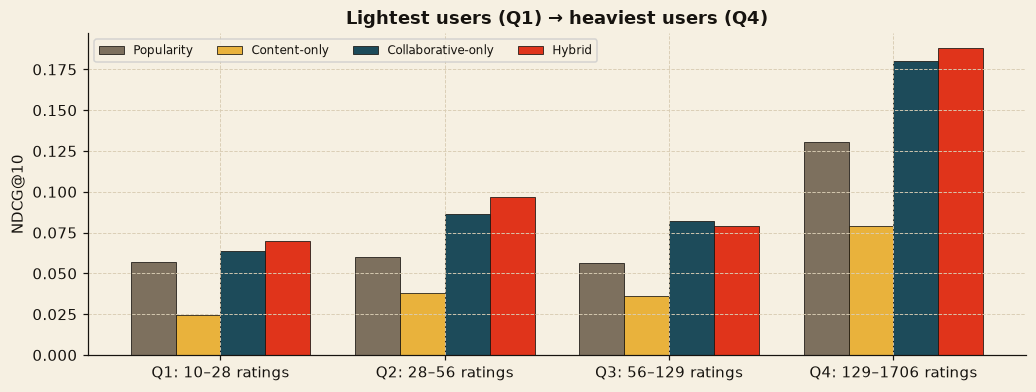

In [20]:
def per_user_ndcg(scores: np.ndarray, k: int) -> dict[int, float]:
    """NDCG@k for every evaluable user."""
    discounts = 1.0 / np.log2(np.arange(2, k + 2))
    out = {}
    for user in range(scores.shape[0]):
        truth, history = test_liked[user], train_seen[user]
        if not truth or not history:
            continue
        user_scores = scores[user].copy()
        user_scores[list(history)] = -np.inf
        top = np.argpartition(-user_scores, k)[:k]
        top = top[np.argsort(-user_scores[top])]
        gains = np.isin(top, list(truth)) * discounts
        out[user] = float(gains.sum() / discounts[: min(k, len(truth))].sum())
    return out


train_activity = np.bincount(dataset.r_user[train_mask], minlength=dataset.n_users)
per_model = {name: per_user_ndcg(scores, CONFIG.top_k) for name, scores in models.items()}
users = np.array(sorted(per_model[hybrid_name]))
edges = np.quantile(train_activity[users], [0, 0.25, 0.5, 0.75, 1.0])
bucket_labels = [f"Q{q + 1}: {int(edges[q])}–{int(edges[q + 1])} ratings" for q in range(4)]
bucket_of = np.clip(np.searchsorted(edges[1:-1], train_activity[users], side="right"), 0, 3)

rows, bar_values = [], {name: [] for name in models}
for q, label in enumerate(bucket_labels):
    members = users[bucket_of == q]
    row = {"Activity bucket": label, "Users": len(members)}
    for name in models:
        value = float(np.mean([per_model[name][u] for u in members]))
        row[name.split(" (")[0]] = value
        bar_values[name].append(value)
    rows.append(row)
show_table(rows, title="NDCG@10 by user activity quartile")

# Let the data speak: where does the hybrid help or hurt relative to collaborative-only?
collab_name = next(n for n in models if n.startswith("Collaborative"))
deltas = [(label, bar_values[hybrid_name][q] / bar_values[collab_name][q] - 1) for q, label in enumerate(bucket_labels)]
display(Markdown("> **Hybrid vs collaborative-only, by quartile:** " + " · ".join(f"{label.split(':')[0]} {d:+.0%}" for label, d in deltas)
                 + f"\n>\n> The largest gain is in **{max(deltas, key=lambda d: d[1])[0].split(':')[0]}** "
                 f"({max(d for _, d in deltas):+.0%}); the lighter half of users (Q1–Q2, closest to a brand-new account) gains "
                 f"{np.mean([deltas[0][1], deltas[1][1]]):+.0%} on average. "
                 + ("Gains are not uniform: " + ", ".join(label.split(':')[0] for label, d in deltas if d < 0)
                    + " is slightly worse, which is a real (small) trade-off rather than noise to hide." if any(d < 0 for _, d in deltas)
                    else "The hybrid improves every quartile.")))

fig, ax = plt.subplots(figsize=(11, 3.8))
width = 0.2
for offset, (name, values) in enumerate(bar_values.items()):
    ax.bar(np.arange(4) + (offset - 1.5) * width, values, width, label=name.split(" (")[0], color=colors[offset], edgecolor=PALETTE["ink"], lw=0.5)
ax.set(xticks=range(4), xticklabels=bucket_labels, ylabel="NDCG@10", title="Lightest users (Q1) → heaviest users (Q4)")
ax.legend(fontsize=8, ncol=4)
plt.show()

### 5.6 Qualitative sanity check: nearest neighbours

**The Goal:** eyeball whether the embedding space "makes sense" to a film fan.

**The Why:** offline metrics can be gamed by popularity. Neighbours that share tone, audience and era (rather than just being popular) show that the model has learned real taste structure. This uses the **exported production artifact**.

In [21]:
def nearest_neighbours(embeddings: np.ndarray, titles: list[str], query: str, n: int = 5) -> list[tuple[str, float]]:
    """Top-n most similar titles to ``query`` by cosine similarity."""
    index = titles.index(query)
    similarity = embeddings @ embeddings[index]
    similarity[index] = -np.inf
    top = np.argsort(-similarity)[:n]
    return [(titles[i], float(similarity[i])) for i in top]


exported_titles = [m["title"] for m in exported_meta["movies"]]
probe_titles = ["Toy Story", "The Matrix", "The Shining", "Pride & Prejudice", "Pulp Fiction"]
show_table([{"If you liked…": q, "…try": ", ".join(f"{t} ({s:.2f})" for t, s in nearest_neighbours(exported, exported_titles, q))}
            for q in probe_titles if q in exported_titles], title="Nearest neighbours in the exported embedding space")

**Nearest neighbours in the exported embedding space**

| If you liked… | …try |
|---|---|
| Toy Story | Toy Story 2 (0.62), Aladdin (0.51), Toy Story 3 (0.49), Babe (0.47), The Incredibles (0.46) |
| The Matrix | Die Hard (0.55), Saving Private Ryan (0.50), Gattaca (0.46), Batman Begins (0.43), The Bourne Identity (0.40) |
| The Shining | Rosemary's Baby (0.58), Donnie Darko (0.46), Léon: The Professional (0.42), Alien Nation (0.40), Pi (0.39) |
| Pride & Prejudice | Julie & Julia (0.76), Pride and Prejudice (0.69), Anchors Aweigh (0.61), The Shipping News (0.59), La La Land (0.59) |
| Pulp Fiction | The Usual Suspects (0.63), Fight Club (0.62), Seven (0.60), Reservoir Dogs (0.59), Fargo (0.51) |

### 5.7 Serving latency

**The Goal:** measure the per-request cost of the production scoring path: fold in a new user from 3 favourites and score the whole catalogue.

**The Why:** the API does this on every page load. It has to be fast enough to need no caching layer or separate model server.

In [22]:
def time_fold_in(embeddings: np.ndarray, popularity: np.ndarray, n_favourites: int = 3, repeats: int = 500) -> np.ndarray:
    """Return per-request latencies (ms) for profile construction + full-catalogue scoring + top-20 selection."""
    rng = np.random.default_rng(CONFIG.seed)
    latencies = np.empty(repeats)
    for r in range(repeats):
        favourites = rng.choice(len(embeddings), n_favourites, replace=False)
        start = time.perf_counter()
        profile = embeddings[favourites].sum(axis=0)
        profile /= np.linalg.norm(profile)
        scores = embeddings @ profile + best_trial.beta * popularity
        top = np.argpartition(-scores, 20)[:20]
        _ = top[np.argsort(-scores[top])]
        latencies[r] = (time.perf_counter() - start) * 1000
    return latencies


exported_popularity = np.array([m["popularity"] for m in exported_meta["movies"]], dtype=np.float32)
latency_ms = time_fold_in(exported, exported_popularity)
show_table([{"Percentile": p, "Latency (ms)": f"{np.percentile(latency_ms, int(p[1:])):.3f}"} for p in ["p50", "p95", "p99"]],
           title=f"Fold-in + scoring {exported.shape[0]:,} movies in NumPy ({len(latency_ms)} simulated requests)")

**Fold-in + scoring 3,650 movies in NumPy (500 simulated requests)**

| Percentile | Latency (ms) |
|---|---|
| p50 | 0.038 |
| p95 | 0.055 |
| p99 | 0.080 |

---
<a id="conclusions"></a>
# ✅ Conclusions & Next Steps

**What we built.** A hybrid recommender that is honest (temporal hold-out, no leakage), diverse (coverage-constrained selection), cold-start friendly (content view + zero-parameter user fold-in) and cheap to serve (~1 MB artifact, sub-millisecond scoring).

> ⚠️ **Performance bottlenecks & caveats**
> - **Popularity bias in the evaluation.** Under a temporal split, what users rate next skews popular, which rewards a large β. That is why selection is coverage-constrained, and why offline gains should be confirmed with an online A/B test (click-through, watchlist adds).
> - **"False positives" are pessimistic.** A recommended film the user never rated counts as a miss, though they may simply not have seen it yet. Absolute precision numbers are therefore lower bounds.
> - **Scaling the SVD.** `scipy.sparse.linalg.svds` is fine at 100k ratings. At `ml-latest` scale (33M ratings, 330k users), switch to randomized SVD or implicit ALS (GPU-capable).
> - **Scaling the scoring.** Brute-force dot products are O(items × dims), which is trivial for 3.6k films. Past ~1M items, use an approximate-nearest-neighbour index (FAISS/ScaNN).
> - **Data loading.** The CSV parsing is pure Python, deliberately: compiled DataFrame libraries were blocked on the development machine. For large datasets, read with `pyarrow`.
> - **Family filter.** MovieLens has no age ratings. The app combines genres and tags as a heuristic; TMDB certifications would make it exact.

**Next steps**
1. Learn the onboarding-quiz weights (genre centroid weight, mood/era boosts) from logged app interactions instead of hand-setting them.
2. Add implicit feedback (watchlist adds, detail-page opens) with confidence weighting (implicit ALS).
3. Retrain nightly in Cloud Build and gate deployment on this notebook's metrics: block the deploy if NDCG@10 or coverage regress.